<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan3/BTOL/ML_T3_BTVOL_B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

So mau, so dac trung: (150, 4)
Cac loai hoa: ['setosa' 'versicolor' 'virginica']
So gia tri thieu: 0

TY LE TRAIN/TEST: 80 / 20

Mo hinh: GaussianNB
Accuracy: 0.9667
Ma tran nham lan:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Mo hinh: MultinomialNB
Accuracy: 0.8333
Ma tran nham lan:
[[10  0  0]
 [ 0  7  3]
 [ 0  2  8]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.78      0.70      0.74        10
   virginica       0.73      0.80      0.76        10

    accuracy                           0.83        30
   macro avg       0.84      0

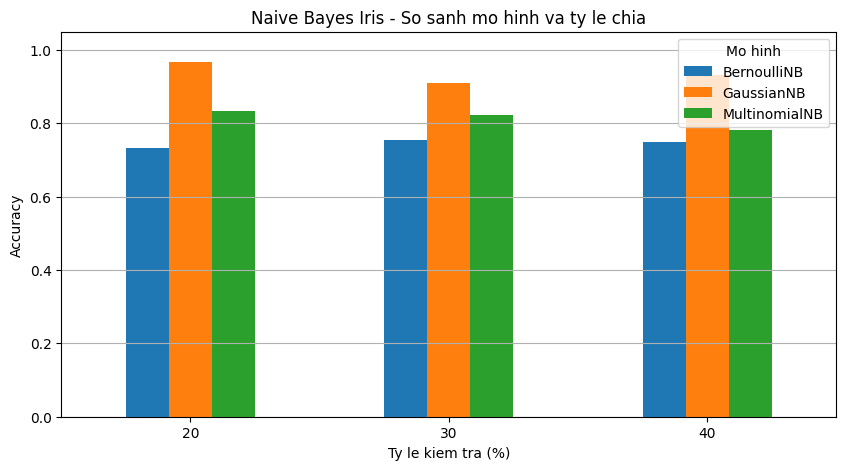

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.preprocessing import MinMaxScaler, Binarizer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Nap du lieu Iris
iris = load_iris()
X = iris.data
y = iris.target

print("So mau, so dac trung:", X.shape)
print("Cac loai hoa:", iris.target_names)
print("So gia tri thieu:", pd.DataFrame(X).isna().sum().sum())

ket_qua = []

# 2. Thu nhieu cach chia
for tile in [0.2, 0.3, 0.4]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=tile, random_state=42, stratify=y
    )

    # Multinomial: du lieu khong am, bien doi tu tap train
    scale = MinMaxScaler()
    X_train_m = scale.fit_transform(X_train)
    X_test_m = scale.transform(X_test)

    # Bernoulli: chuyen thanh 0/1 voi nguong cua train
    nguong = X_train.mean(axis=0)
    X_train_b = (X_train > nguong).astype(int)
    X_test_b = (X_test > nguong).astype(int)

    models = [
        ("GaussianNB", GaussianNB(), X_train, X_test),
        ("MultinomialNB", MultinomialNB(), X_train_m, X_test_m),
        ("BernoulliNB", BernoulliNB(), X_train_b, X_test_b)
    ]

    print("\nTY LE TRAIN/TEST:", int((1-tile)*100), "/", int(tile*100))

    for ten, model, train, test in models:
        model.fit(train, y_train)
        pred = model.predict(test)

        acc = accuracy_score(y_test, pred)
        ket_qua.append({
            "Ty le test": int(tile * 100),
            "Mo hinh": ten,
            "Accuracy": acc
        })

        print("\nMo hinh:", ten)
        print("Accuracy:", round(acc, 4))
        print("Ma tran nham lan:")
        print(confusion_matrix(y_test, pred))
        print(classification_report(
            y_test, pred,
            target_names=iris.target_names,
            zero_division=0
        ))

# 3. Tong hop so sanh
df = pd.DataFrame(ket_qua)
bang = df.pivot(
    index="Ty le test",
    columns="Mo hinh",
    values="Accuracy"
)

print("\nBANG SO SANH ACCURACY:")
print(bang.round(4))

# 4. Truc quan hoa
bang.plot(kind="bar", figsize=(10, 5))
plt.title("Naive Bayes Iris - So sanh mo hinh va ty le chia")
plt.xlabel("Ty le kiem tra (%)")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()
